John S. Anvik, 2026  
University of Lethbridge Student ID: 001224816

Import Packages

In [ ]:
library(tidyverse)
library(tidymodels)
library(rpart.plot)
library(vip)
library(ranger)
library(furrr)
set.seed(42)
MODEL_NAME <- "candidate_match"


Installing package into 'C:/Users/johna/AppData/Local/R/win-library/4.5'
(as 'lib' is unspecified)



package 'furrr' successfully unpacked and MD5 sums checked

The downloaded binary packages are in
	C:\Users\johna\AppData\Local\Temp\RtmpYdAG3T\downloaded_packages


Warning message:
"package 'furrr' was built under R version 4.5.3"
Loading required package: future

Warning message:
"package 'future' was built under R version 4.5.3"


Load candidate-level data exported by notebook 2

In [3]:
candidate_files <- list.files("data/by_id", pattern = "_candidate_classification\\.csv$", full.names = TRUE)

# To test only a single classifier, uncomment the next line:
# candidate_files <- candidate_files[1]

model_data_by_male <- flatten(map(candidate_files, function(candidate_file) {
    song_data <- read_csv(candidate_file, show_col_types = FALSE)
    focal_ids <- song_data %>% distinct(ID) %>% pull(ID)
    focal_numbers <- song_data %>% pull(male_number) %>% as.character() %>% unique() %>% na.omit()
    if (length(focal_ids) != 1 || length(focal_numbers) == 0) {
        stop(sprintf("Expected one focal ID and at least one male_number in %s", candidate_file))
    }
    map(focal_numbers, function(focal_number) {
        focal_rows <- song_data %>% filter(as.character(male_number) == focal_number)
        male_prefix <- paste0("M", focal_number)
        required_columns <- c(
            "event_id", "candidate_ust", "match", "candidate_n_ust_window",
            paste0("candidate_matches_", male_prefix, "_1_last_UST"),
            paste0("candidate_matches_", male_prefix, "_2_last_UST"),
            paste0("time_since_", male_prefix, "_1_last_song"),
            paste0("time_since_", male_prefix, "_2_last_song")
        )
        missing_columns <- setdiff(required_columns, names(focal_rows))
        if (length(missing_columns) > 0) {
            stop(sprintf("Missing required columns in %s for %s: %s", candidate_file, male_prefix, paste(missing_columns, collapse = ", ")))
        }
        focal_rows %>%
            transmute(
                focal_male = paste0(focal_ids, "_", male_prefix),
                focal_id = focal_ids,
                male_number = focal_number,
                event_id,
                candidate_ust = as.factor(as.character(candidate_ust)),
                match,
                candidate_n_ust_window,
                focal_last_1_candidate = .data[[paste0("candidate_matches_", male_prefix, "_1_last_UST")]],
                focal_last_2_candidate = .data[[paste0("candidate_matches_", male_prefix, "_2_last_UST")]],
                focal_time_since_last_1 = .data[[paste0("time_since_", male_prefix, "_1_last_song")]],
                focal_time_since_last_2 = .data[[paste0("time_since_", male_prefix, "_2_last_song")]]
            ) %>%
            mutate(match_class = factor(if_else(match == 1, "match", "no_match"), levels = c("no_match", "match"))) %>%
            select(-match)
    })
}))
names(model_data_by_male) <- map_chr(model_data_by_male, ~ unique(.x$focal_male))

walk(model_data_by_male, function(male_data) {
    event_checks <- male_data %>% group_by(event_id) %>% summarise(n_candidates = n(), n_matches = sum(match_class == "match"), .groups = "drop")
    if (any(event_checks$n_candidates < 2) || any(event_checks$n_matches != 1)) {
        stop(sprintf("Invalid candidate events for %s", unique(male_data$focal_male)))
    }
})

In [4]:
map_dfr(model_data_by_male, ~ .x %>% summarise(
    focal_male = first(focal_male),
    n_events = n_distinct(event_id),
    n_candidate_rows = n(),
    n_song_types = n_distinct(candidate_ust)
))

focal_male,n_events,n_candidate_rows,n_song_types
<chr>,<int>,<int>,<int>
DgTbO_M5,1167,32676,28
DgTbO_M6,999,27972,28
KLgK_M5,516,9804,19
KRDg_M2,1021,26546,26
LbOW_M1,699,12582,18
RbDgY_M2,656,13776,21
RRO_M6,535,10165,19
TbTbLg_M4,734,13946,19
TbWY_M1,604,10268,17


Train/test split and cross-validation

In [5]:
male_splits <- map(model_data_by_male, ~ group_initial_split(.x, group = event_id, prop = 0.7))
male_train_data <- map(male_splits, training)
male_test_data <- map(male_splits, testing)
male_vfolds <- map(male_train_data, ~ group_vfold_cv(.x, group = event_id, v = 5))

Data preprocessing using a recipe

In [6]:
male_recipes <- map(male_train_data, ~ recipe(match_class ~ ., data = .x) %>% update_role(focal_male, focal_id, male_number, event_id, candidate_ust, new_role = "id") %>% step_impute_median(all_numeric_predictors()))

Tune using top-1 candidate-selection accuracy

In [7]:
# ---- Settings ---------------------------------------------------------------
rf_grid     <- tidyr::crossing(mtry = c(1, 2, 3, 4, 5), min_n = c(2, 5, 10, 15, 20))
tune_trees  <- 300    # fewer trees while tuning
final_trees <- 1000   # full forest only for the final model

# Fast top-1 accuracy (assumes exactly one true "match" row per event)
top1_candidate_accuracy <- function(predictions) {
    dt <- as.data.table(predictions)
    dt[dt[, .I[which.max(.pred_match)], by = event_id]$V1,
       mean(match_class == "match")]
}

# Spec builder: importance off by default
make_spec <- function(mtry, min_n, trees, importance = "none", threads = 1) {
    rand_forest(mtry = mtry, trees = trees, min_n = min_n) %>%
        set_engine("ranger", importance = importance, probability = TRUE,
                   num.threads = threads) %>%
        set_mode("classification")
}

# Prep + bake each fold once.
# NOTE: assumes the recipe never drops or reorders rows.
prep_folds <- function(vfolds, model_recipe) {
    map(vfolds$splits, function(split) {
        assess <- assessment(split)
        rec <- prep(model_recipe, training = analysis(split))
        list(
            train = bake(rec, new_data = NULL,   all_predictors(), all_outcomes()),
            test  = bake(rec, new_data = assess, all_predictors(), all_outcomes()),
            meta  = assess %>% select(event_id, match_class)
        )
    })
}

fit_one_male <- function(male_data, train_data, test_data, vfolds, model_recipe,
                         threads = 1) {
    setDTthreads(1)
    focal_male <- unique(male_data$focal_male)
    folds <- prep_folds(vfolds, model_recipe)

    tuning_results <- pmap_dfr(rf_grid, function(mtry, min_n) {
        spec <- make_spec(mtry, min_n, trees = tune_trees, threads = threads)
        acc <- map_dbl(folds, function(f) {
            fit_i <- fit(spec, match_class ~ ., data = f$train)
            preds <- predict(fit_i, f$test, type = "prob") %>% bind_cols(f$meta)
            top1_candidate_accuracy(preds)
        })
        tibble(mtry = mtry, min_n = min_n,
               mean_top1_accuracy = mean(acc),
               std_error = sd(acc) / sqrt(length(acc)))
    }) %>% arrange(desc(mean_top1_accuracy), std_error)

    best_params <- tuning_results %>% slice(1)

    final_spec <- make_spec(best_params$mtry, best_params$min_n,
                            trees = final_trees, importance = "impurity",
                            threads = threads)
    final_model <- workflow() %>%
        add_recipe(model_recipe) %>%
        add_model(final_spec) %>%
        fit(data = train_data)

    test_predictions <- predict(final_model, test_data, type = "prob") %>%
        bind_cols(test_data %>% select(focal_male, event_id, candidate_ust, match_class))

    song_levels <- levels(male_data$candidate_ust)

    event_predictions <- test_predictions %>%
        group_by(event_id) %>%
        arrange(desc(.pred_match), .by_group = TRUE) %>%
        summarise(focal_male = first(focal_male),
                  predicted_song_type = first(candidate_ust),
                  actual_song_type = candidate_ust[match_class == "match"][1],
                  .groups = "drop") %>%
        mutate(predicted_song_type = factor(predicted_song_type, levels = song_levels),
               actual_song_type    = factor(actual_song_type,    levels = song_levels))

    ranking_metrics <- test_predictions %>%
        group_by(event_id) %>%
        arrange(desc(.pred_match), .by_group = TRUE) %>%
        mutate(candidate_rank = row_number(),
               actual_match = match_class == "match") %>%
        summarise(top1_correct = any(candidate_rank == 1 & actual_match),
                  top3_correct = any(candidate_rank <= 3 & actual_match),
                  reciprocal_rank = 1 / min(candidate_rank[actual_match]),
                  correct_rank = min(candidate_rank[actual_match]),
                  .groups = "drop")

    metrics <- tibble(
        focal_male = focal_male,
        n_test_events = nrow(event_predictions),
        accuracy = mean(ranking_metrics$top1_correct),
        macro_precision = precision(event_predictions, truth = actual_song_type,
                                    estimate = predicted_song_type, estimator = "macro")$.estimate,
        macro_recall = recall(event_predictions, truth = actual_song_type,
                              estimate = predicted_song_type, estimator = "macro")$.estimate,
        top3_recall = mean(ranking_metrics$top3_correct),
        mean_reciprocal_rank = mean(ranking_metrics$reciprocal_rank),
        mean_rank = mean(ranking_metrics$correct_rank)
    )

    list(focal_male = focal_male, tuning_results = tuning_results,
         best_params = best_params, model = final_model,
         test_predictions = test_predictions, event_predictions = event_predictions,
         metrics = metrics)
}

# Run in parallel across males (one ranger thread per worker)
plan(multisession, workers = max(1, parallel::detectCores() - 1))

male_results <- future_pmap(
    list(model_data_by_male, male_train_data, male_test_data, male_vfolds, male_recipes),
    fit_one_male,
    threads = 1,
    .options = furrr_options(
        seed = TRUE,
        packages = c("tidymodels", "ranger", "data.table", "dplyr", "purrr", "tibble"),
        globals = c("rf_grid", "tune_trees", "final_trees",
                    "top1_candidate_accuracy", "make_spec", "prep_folds")
    )
)

plan(sequential)

Warning message:
"package 'future' was built under R version 4.5.3"
Warning message:
"package 'purrr' was built under R version 4.5.3"
Warning message:
"package 'tidymodels' was built under R version 4.5.3"
Warning message:
"package 'broom' was built under R version 4.5.3"
Warning message:
"package 'dials' was built under R version 4.5.3"
Warning message:
"package 'dplyr' was built under R version 4.5.3"
Warning message:
"package 'ggplot2' was built under R version 4.5.3"
Warning message:
"package 'infer' was built under R version 4.5.3"
Warning message:
"package 'modeldata' was built under R version 4.5.3"
Warning message:
"package 'parsnip' was built under R version 4.5.3"
Warning message:
"package 'recipes' was built under R version 4.5.3"
Warning message:
"package 'rsample' was built under R version 4.5.3"
Warning message:
"package 'tidyr' was built under R version 4.5.3"
Warning message:
"package 'tune' was built under R version 4.5.3"
Warning message:
"package 'yardstick' was bui

Select best hyperparameters and refit on all training data

In [8]:
map_dfr(male_results, "best_params") %>% select(mtry, min_n, mean_top1_accuracy, std_error)

mtry,min_n,mean_top1_accuracy,std_error
<dbl>,<dbl>,<dbl>,<dbl>
1,20,0.09914709,0.008772091
2,10,0.15164440,0.015872405
3,2,0.11362253,0.008238753
1,20,0.14545455,0.013523832
1,5,0.14929518,0.011931107
1,5,0.16779742,0.024039404
1,15,0.17380180,0.032389942
1,2,0.13424710,0.008371492
1,5,0.16316527,0.013315049


Evaluate held-out test data

In [9]:
per_male_metrics <- map_dfr(male_results, "metrics")
per_male_metrics

focal_male,n_test_events,accuracy,macro_precision,macro_recall,top3_recall,mean_reciprocal_rank,mean_rank
<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
DgTbO_M5,350,0.1514286,0.11564233,0.13380931,0.2742857,0.2702980,12.922857
DgTbO_M6,300,0.1233333,0.11170270,0.07962806,0.2766667,0.2660056,11.390000
KLgK_M5,155,0.1225806,0.13624748,0.13455861,0.3225806,0.2880223,8.000000
KRDg_M2,306,0.1078431,0.06423542,0.05580167,0.2745098,0.2584806,10.042484
LbOW_M1,210,0.1095238,0.12855433,0.18325909,0.3238095,0.2867574,7.566667
RbDgY_M2,197,0.1522843,0.08951506,0.08693773,0.3756345,0.3312721,6.223350
RRO_M6,161,0.1614907,0.14488688,0.10093985,0.3602484,0.3262272,7.447205
TbTbLg_M4,220,0.1181818,0.08231248,0.11091193,0.2636364,0.2782545,7.386364
TbWY_M1,181,0.2154696,0.13996492,0.17112566,0.4475138,0.3973848,5.209945


Confusion matrix

In [10]:
map(male_results, ~ conf_mat(.x$event_predictions, truth = actual_song_type, estimate = predicted_song_type))

$DgTbO_M5
          Truth
Prediction  1 10 11 12 13 15 153 154 155 156 157 158 159 160 161 162 163 164 20
       1    4  3  2  0  0  0   5   0   0   0   0   0   0   0   0   0   0   0 10
       10   3 11  5  1  0  0   2   0   0   0   0   0   0   0   0   0   0   0  7
       11   0  1  0  0  0  0   1   0   0   0   0   0   0   0   0   0   0   0  1
       12   0  0  2  2  0  1   0   0   1   0   0   0   0   0   0   0   0   0  1
       13   2  3  1  1  0  0   1   0   0   0   0   0   0   0   0   0   0   0  6
       15   0  1  0  0  0  0   1   0   0   0   0   0   0   0   0   0   0   0  0
       153  2  2  0  0  0  0   3   0   0   0   0   0   0   0   0   0   0   0  2
       154  0  0  0  0  0  0   0   0   0   0   0   0   0   0   0   0   0   0  0
       155  0  0  0  0  0  0   0   0   0   0   0   0   0   0   0   0   0   0  0
       156  0  0  0  0  0  0   0   0   0   0   0   0   0   0   0   0   0   0  0
       157  0  0  0  0  0  0   0   0   0   0   0   0   0   0   0   0   0   0  0
       158  0 

Feature importance

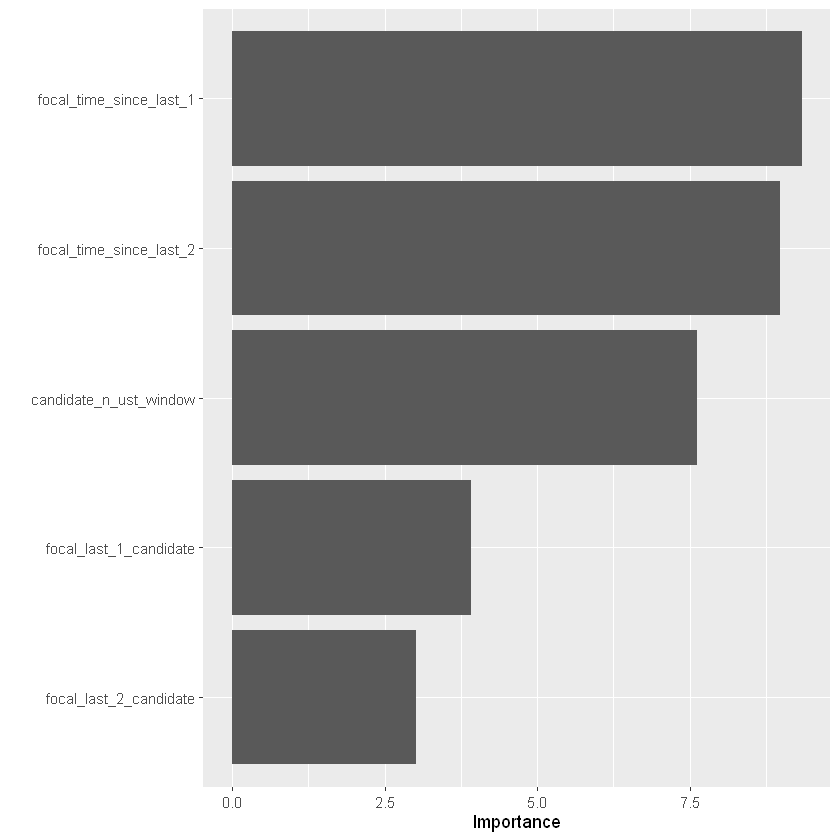

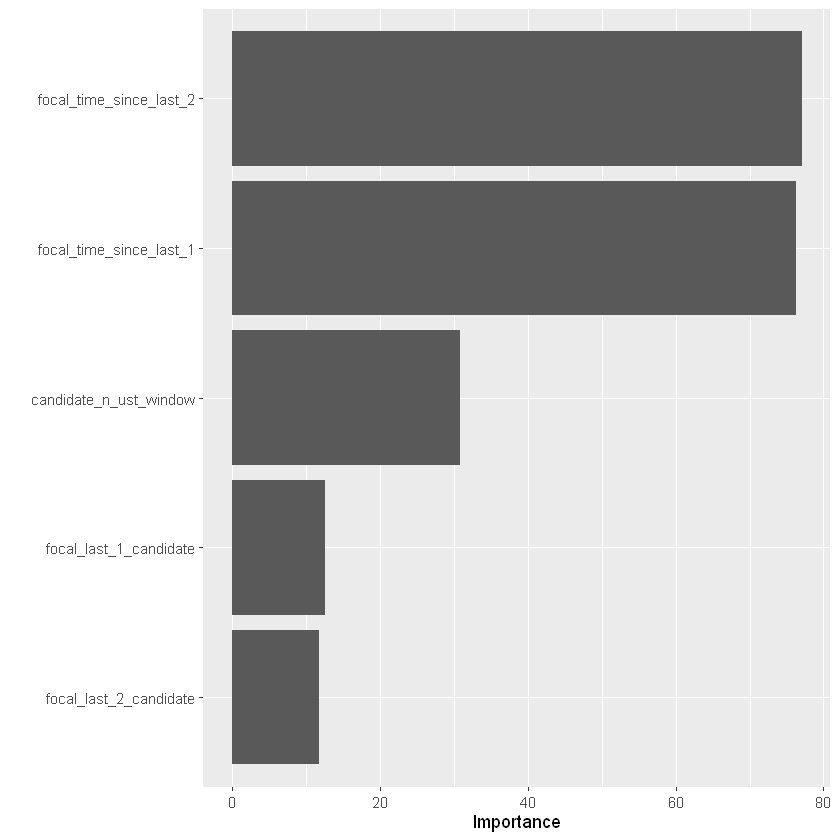

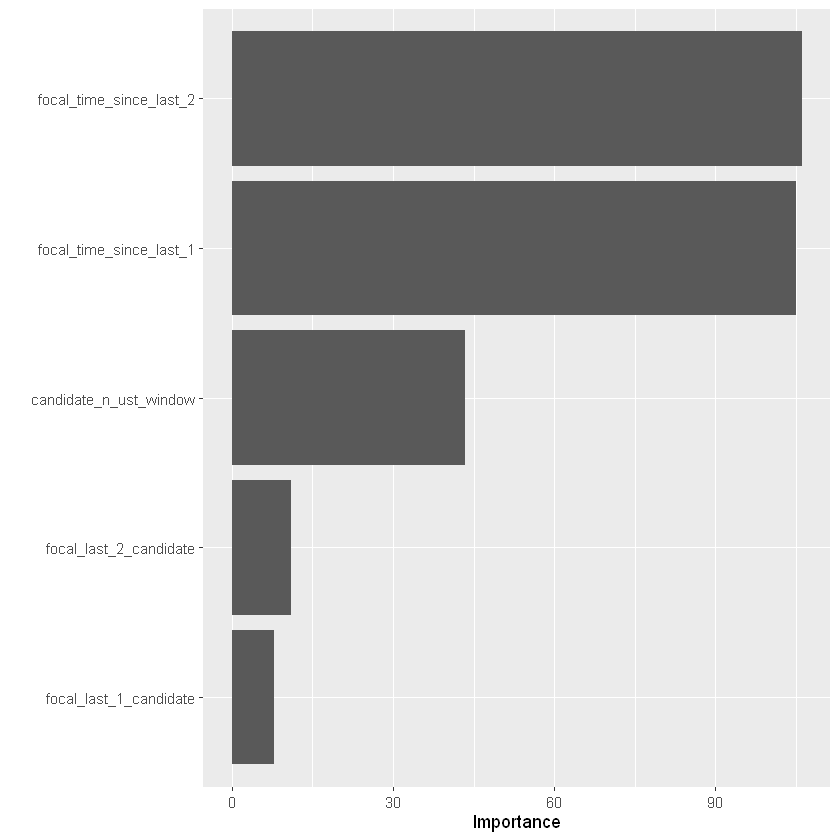

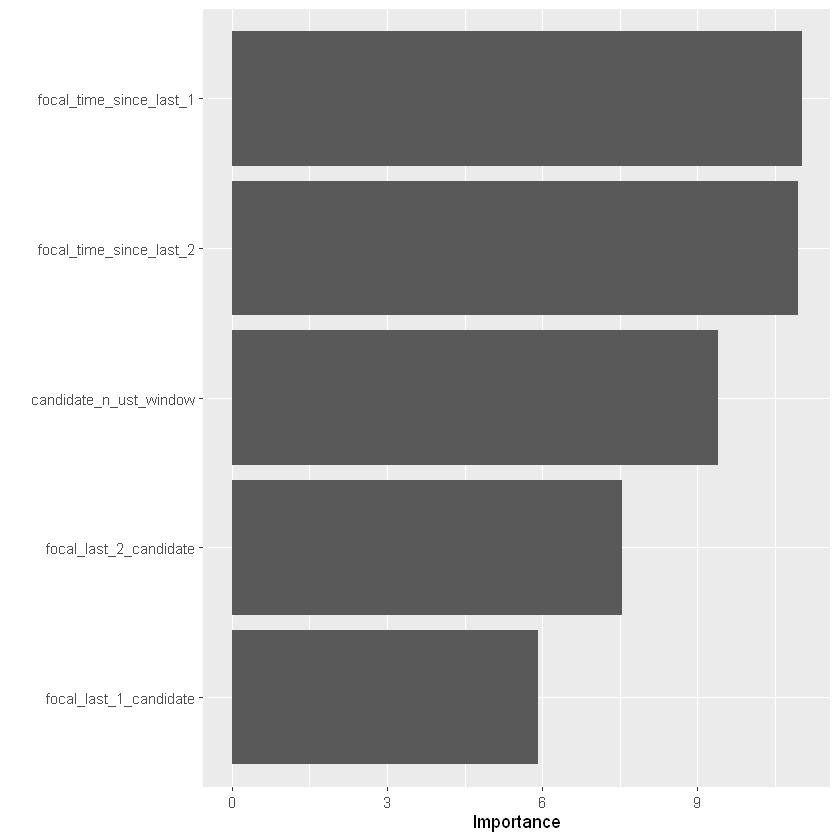

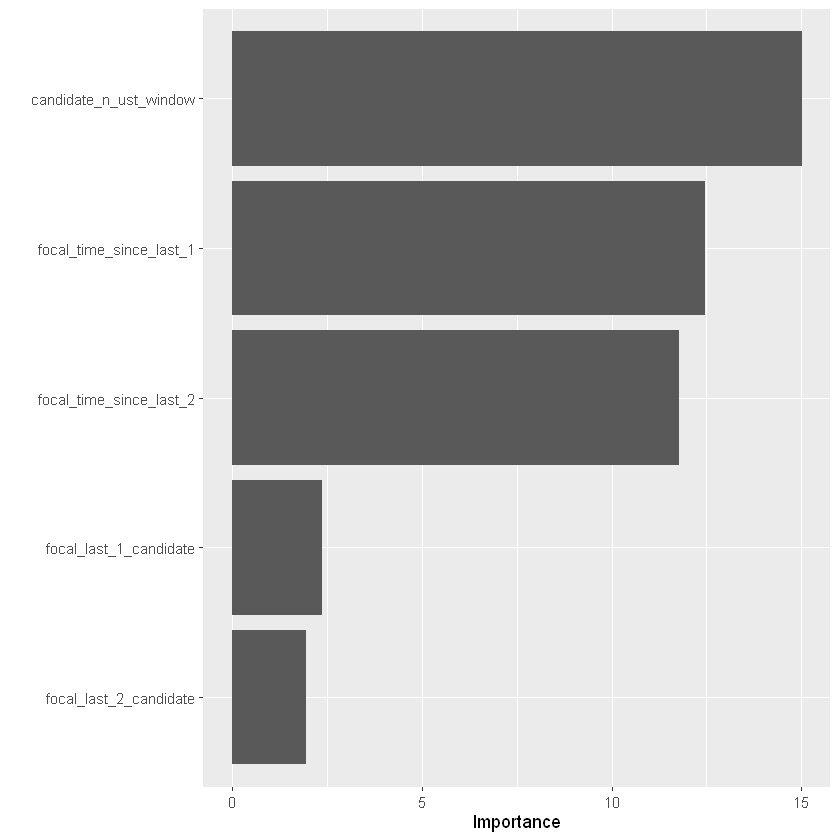

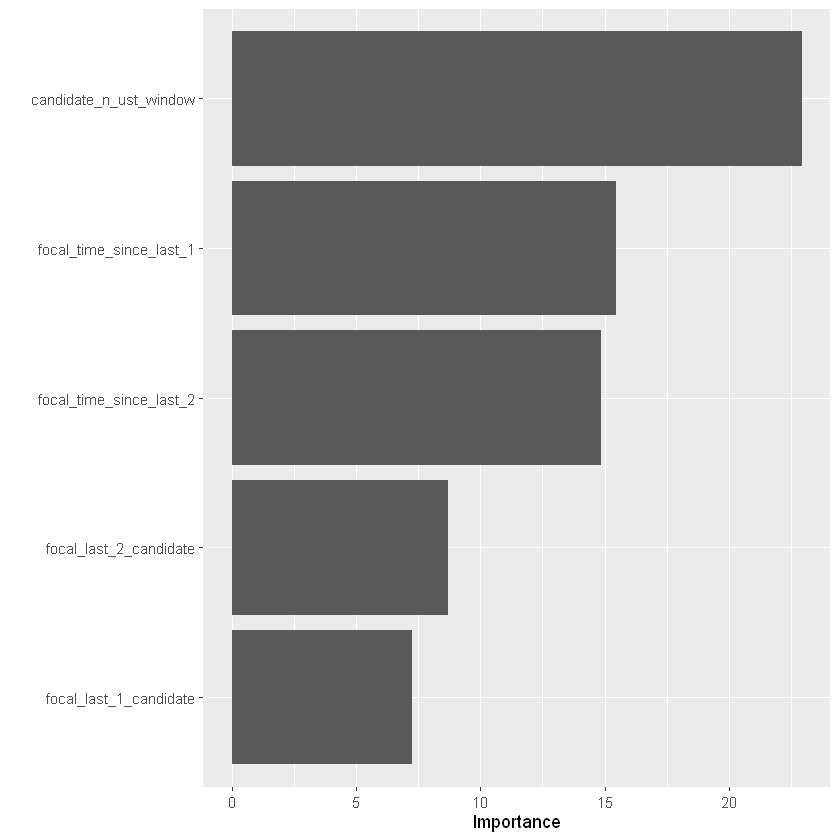

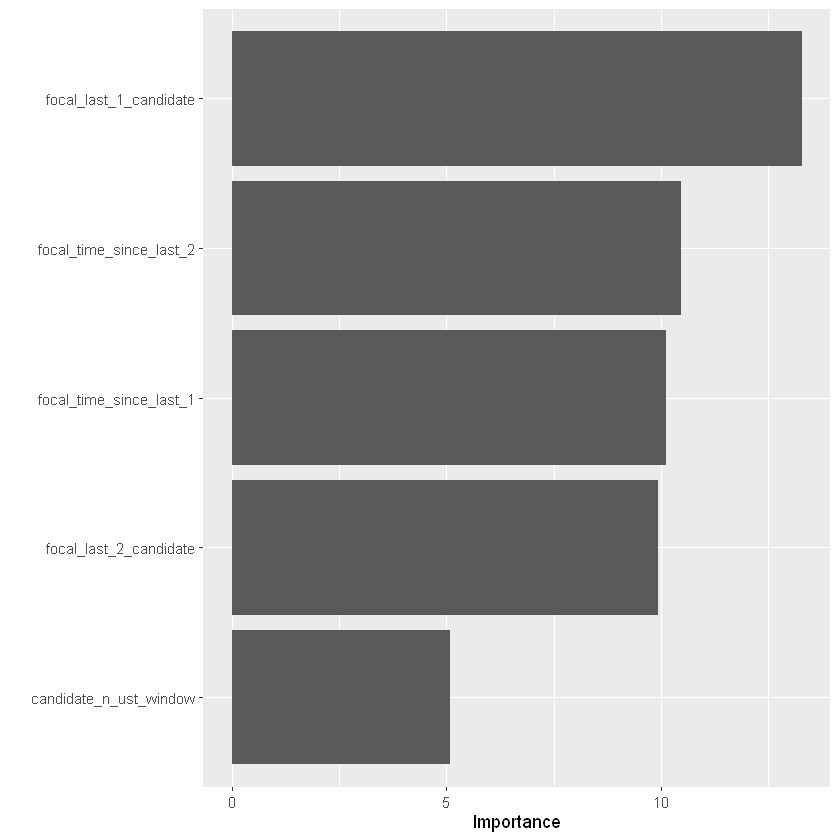

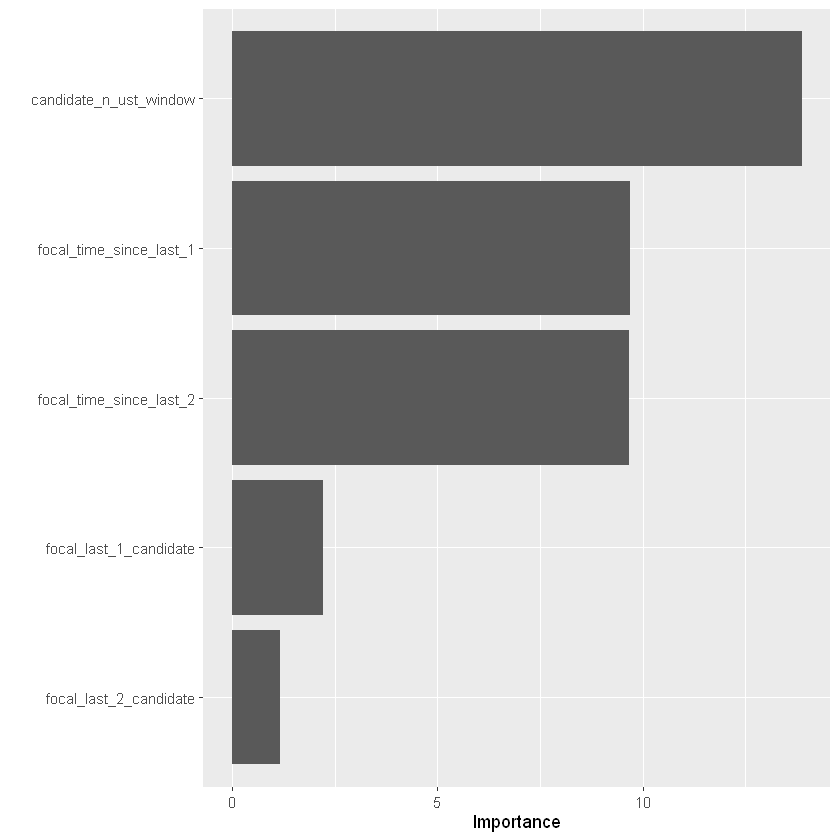

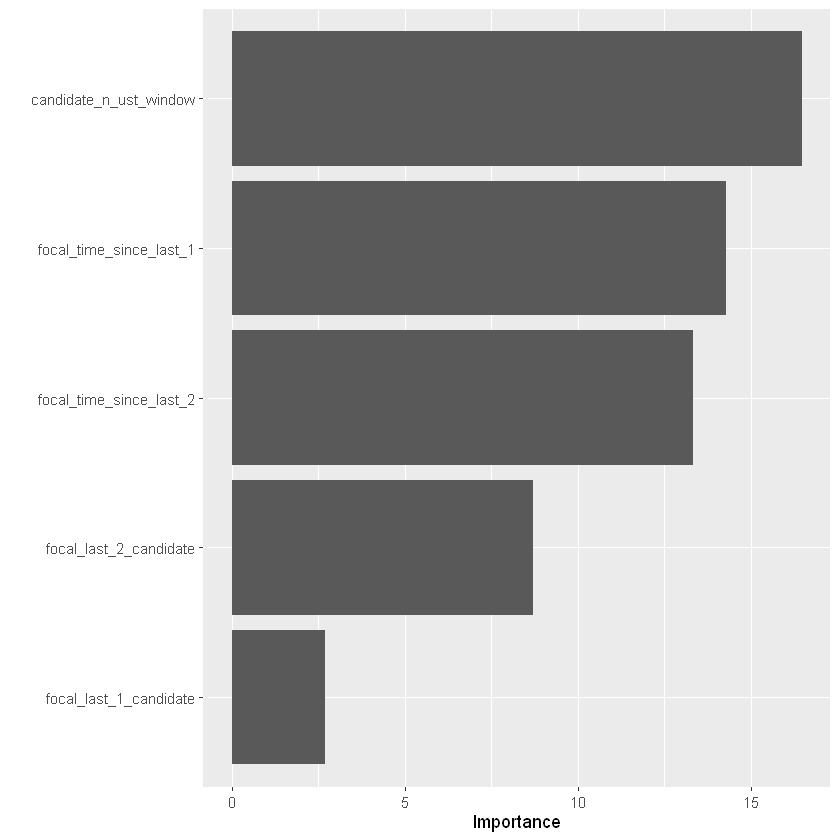

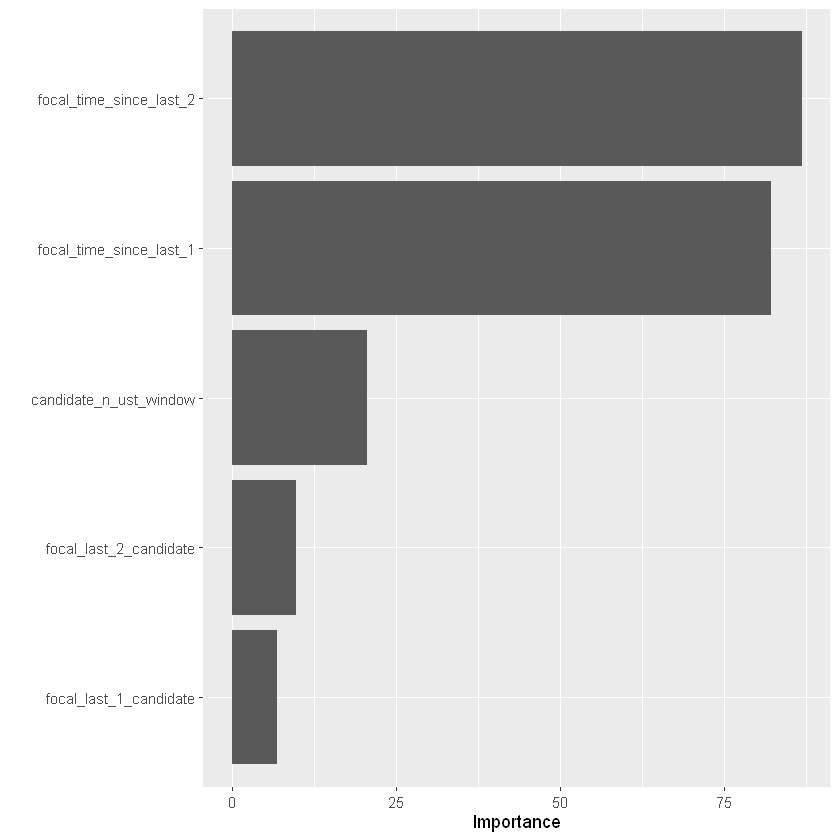

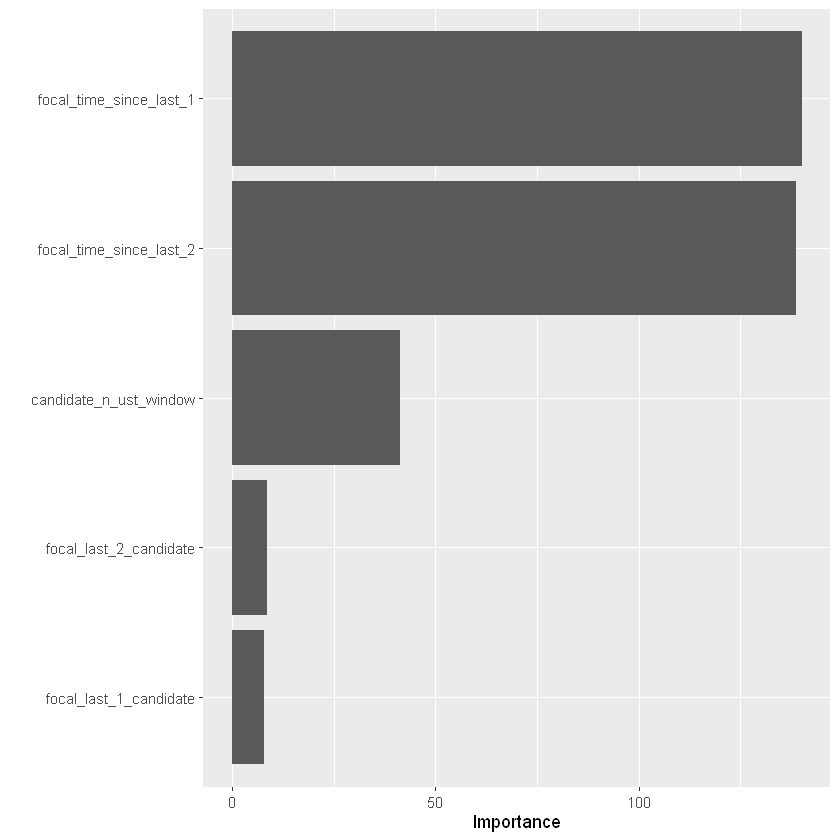

In [11]:
walk(male_results, ~ print(vip(.x$model %>% extract_fit_engine(), num_features = 5)))

Candidate-ranking metrics

In [12]:
per_male_metrics %>% summarise(macro_accuracy = mean(accuracy), macro_top3_recall = mean(top3_recall), macro_mean_reciprocal_rank = mean(mean_reciprocal_rank), macro_mean_rank = mean(mean_rank))

macro_accuracy,macro_top3_recall,macro_mean_reciprocal_rank,macro_mean_rank
<dbl>,<dbl>,<dbl>,<dbl>
0.1420444,0.3271091,0.3007119,8.533893


In [13]:
# Save model results using the model name defined above.
dir.create("data/2026_results", recursive = TRUE, showWarnings = FALSE)

per_male_metrics <- map_dfr(male_results, "metrics")
all_event_predictions <- map_dfr(male_results, ~ .x$event_predictions)
all_tuning_results <- map2_dfr(male_results, names(male_results), ~ .x$tuning_results %>% mutate(focal_male = .y))

write_csv(per_male_metrics, file.path("data/2026_results", paste0(MODEL_NAME, "_test_metrics.csv")))
write_csv(all_event_predictions, file.path("data/2026_results", paste0(MODEL_NAME, "_event_predictions.csv")))
write_csv(all_tuning_results, file.path("data/2026_results", paste0(MODEL_NAME, "_tuning_results.csv")))
saveRDS(male_results, file.path("data/2026_results", paste0(MODEL_NAME, "_models.rds")))

walk(male_results, function(result) {
    importance_chart <- result$model %>%
        extract_fit_engine() %>%
        vip(num_features = 10) +
        labs(title = paste(result$focal_male, MODEL_NAME)) +
        theme_bw()
    ggsave(
        file.path("data/2026_results", paste0(MODEL_NAME, "_", result$focal_male, "_importance.png")),
        plot = importance_chart,
        width = 8,
        height = 6,
        units = "in"
    )
})

per_male_metrics

focal_male,n_test_events,accuracy,macro_precision,macro_recall,top3_recall,mean_reciprocal_rank,mean_rank
<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
DgTbO_M5,350,0.1514286,0.11564233,0.13380931,0.2742857,0.2702980,12.922857
DgTbO_M6,300,0.1233333,0.11170270,0.07962806,0.2766667,0.2660056,11.390000
KLgK_M5,155,0.1225806,0.13624748,0.13455861,0.3225806,0.2880223,8.000000
KRDg_M2,306,0.1078431,0.06423542,0.05580167,0.2745098,0.2584806,10.042484
LbOW_M1,210,0.1095238,0.12855433,0.18325909,0.3238095,0.2867574,7.566667
RbDgY_M2,197,0.1522843,0.08951506,0.08693773,0.3756345,0.3312721,6.223350
RRO_M6,161,0.1614907,0.14488688,0.10093985,0.3602484,0.3262272,7.447205
TbTbLg_M4,220,0.1181818,0.08231248,0.11091193,0.2636364,0.2782545,7.386364
TbWY_M1,181,0.2154696,0.13996492,0.17112566,0.4475138,0.3973848,5.209945
